In [4]:
from pathlib import Path
import duckdb
import numpy as np
import matplotlib.pyplot as plt


#Folders 
root = Path.cwd().parent
proc = root / "data" / "processed"
sql_dir = root / "sql"
figs = root / "reports" / "figures"
figs.mkdir(parents=True, exist_ok=True)

#Duckdb with memory limits
con = duckdb.connect()
con.execute("SET memory_limit = '1.5GB'")
con.execute("SET threads = 2")
tmp = root / "data" / "duckdb_tmp"
tmp.mkdir(parents=True, exist_ok=True)
con.execute(f"SET temp_directory = '{tmp.as_posix()}'")


# Give each Parquet file a table name
for table, file in [("transactions", "transactions_train"),
                    ("customers", "customers"),
                    ("articles", "articles")]:
    con.execute(f"CREATE VIEW {table} AS SELECT * FROM '{(proc / f'{file}.parquet').as_posix()}'")

def run_sql(filename):
    """Read a .sql file from the sql/ folder and run it."""
    return con.sql((sql_dir / filename).read_text()).df()

print(con.sql("SELECT count(*) AS n FROM transactions").df())


          n
0  31788324


The Purchase funnel

In [14]:
funnel = run_sql("01_funnel.sql")
funnel["pct_of_start"] = (100 * funnel["customers"] / funnel["customers"].iloc[0]).round(1)
funnel["pct_of_previous"] = (100 * funnel["customers"] / funnel["customers"].shift(1)).round(1)
funnel

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,stage,customers,pct_of_start,pct_of_previous
0,1. First trip,1189917,100.0,NaN
1,2. Second trip,859334,72.2,72.2
2,3. Third trip,707430,59.5,82.3
3,4. Fifth trip,527508,44.3,74.6


Plotting it

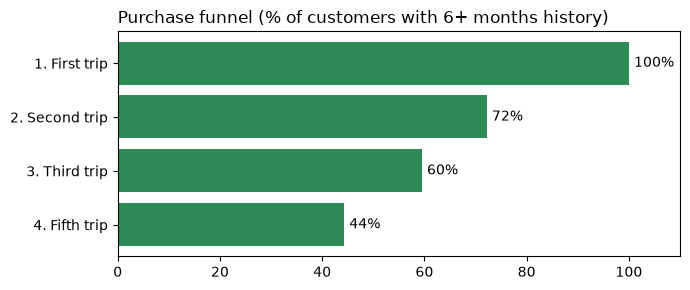

In [20]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(funnel["stage"][::-1], funnel["pct_of_start"][::-1], color="seagreen")
for y, v in enumerate(funnel["pct_of_start"][::-1]):
    ax.text(v + 1, y, f"{v:.0f}%", va="center")
ax.set_xlim(0, 110)
ax.set_title("Purchase funnel (% of customers with 6+ months history)", loc="left")
plt.tight_layout()
plt.savefig(figs / "funnel.png", dpi=150)
plt.show()

In [21]:
coh = run_sql("02_cohort_retention.sql")
coh.head(15)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,cohort_month,months_since_first,active_customers,cohort_customers,retention_pct
0,2018-09-01,0,140340,140340,100.00
1,2018-09-01,1,61551,140340,43.86
2,2018-09-01,2,59793,140340,42.61
3,2018-09-01,3,56736,140340,40.43
4,2018-09-01,4,53683,140340,38.25
5,2018-09-01,5,50781,140340,36.18
6,2018-09-01,6,53249,140340,37.94
7,2018-09-01,7,55296,140340,39.40
8,2018-09-01,8,55332,140340,39.43
9,2018-09-01,9,59931,140340,42.70


In [22]:
coh_12 = coh[coh["months_since_first"].between(1, 12)]
pivot = coh_12.pivot(index="cohort_month",
                     columns="months_since_first",
                     values="retention_pct")
pivot.round(1)

months_since_first,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,
2018-09-01,43.9,42.6,40.4,38.2,36.2,37.9,39.4,39.4,42.7,40.9,34.5,36.4
2018-10-01,35.8,33.4,31.7,29.6,31.1,32.6,33.0,35.8,34.7,28.2,28.9,29.8
2018-11-01,26.4,23.9,22.2,23.6,24.6,25.3,28.0,26.8,21.3,21.7,22.1,23.8
2018-12-01,21.1,18.5,19.4,20.5,21.2,23.7,23.4,18.1,17.9,18.4,19.2,20.4
2019-01-01,18.0,17.9,18.8,19.2,21.2,20.8,16.0,16.3,16.6,17.0,16.6,15.4
2019-02-01,17.2,16.9,17.1,18.8,18.3,14.0,14.0,14.3,14.8,14.1,12.9,13.0
2019-03-01,19.4,18.4,20.3,19.1,14.4,15.0,15.1,15.8,14.9,13.2,13.2,12.0
2019-04-01,19.2,19.5,18.3,13.6,13.4,14.2,14.8,13.7,11.8,12.2,10.8,12.4
2019-05-01,20.5,17.9,13.1,13.3,13.4,13.9,13.5,11.5,11.3,10.5,11.3,12.9


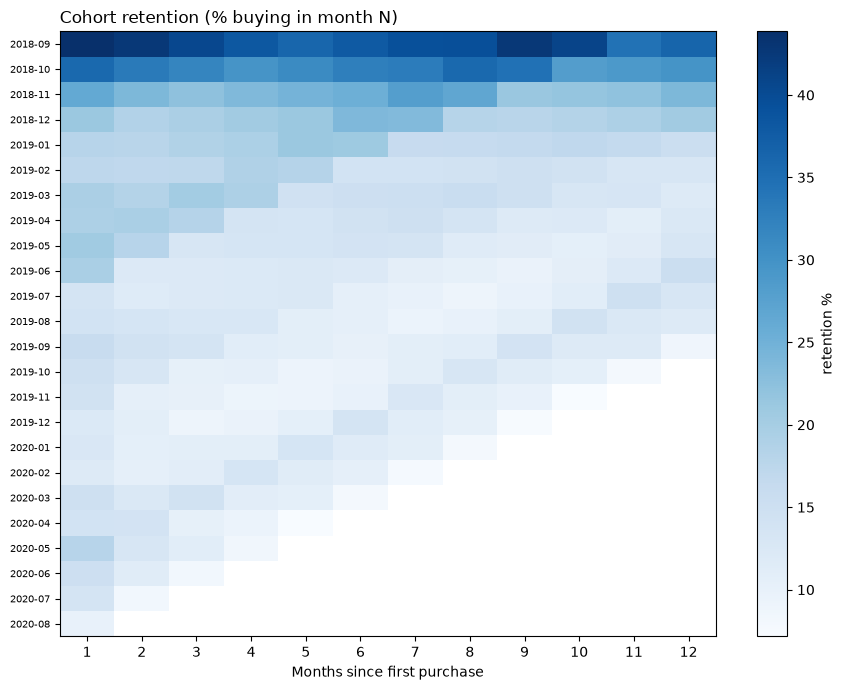

In [23]:
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(pivot.to_numpy(), aspect="auto", cmap="Blues")
ax.set_yticks(range(len(pivot)), [d.strftime("%Y-%m") for d in pivot.index], fontsize=7)
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_xlabel("Months since first purchase")
ax.set_title("Cohort retention (% buying in month N)", loc="left")
fig.colorbar(im, ax=ax, label="retention %")
plt.tight_layout()
plt.savefig(figs / "cohort_retention.png", dpi=150)
plt.show()

In [24]:
m1 = coh[coh["months_since_first"] == 1]["retention_pct"].median()
m3 = coh[coh["months_since_first"] == 3]["retention_pct"].median()
print(f"Median retention: month 1 = {m1:.1f}%, month 3 = {m3:.1f}%")

Median retention: month 1 = 15.5%, month 3 = 13.0%


In [25]:
clean = coh[coh["cohort_month"] >= "2018-12-01"]
m1 = clean[clean["months_since_first"] == 1]["retention_pct"].median()
m3 = clean[clean["months_since_first"] == 3]["retention_pct"].median()
print(f"Median retention (cohorts Dec 2018+): month 1 = {m1:.1f}%, month 3 = {m3:.1f}%")

Median retention (cohorts Dec 2018+): month 1 = 14.8%, month 3 = 12.1%


RFM Segment: To identify which kind of customers drive the revenue, and whcih valuable ones are slipping away.

Recency: how many days since their last purchase(lower is better)
Frequency: how many shopping trips they've made
Monetary: how much they've spent in total

Customers are then grouped into segments such as "Champions" (brought recently and often) or "At risk" (used to buy often, but not lately)

In [7]:
rfm = run_sql("03_rfm.sql")
rfm

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,segment,customers,pct_customers,pct_revenue,avg_recency_days,avg_trips
0,Champions,372813,27.4,67.3,37.0,16.4
1,Loyal,217111,15.9,15.7,118.0,6.3
2,At risk,141268,10.4,8.2,381.0,5.4
3,Hibernating / lost,403645,29.6,5.4,504.0,1.2
4,Needs attention,124735,9.2,1.9,159.0,1.3
5,New / promising,102709,7.5,1.5,48.0,1.4


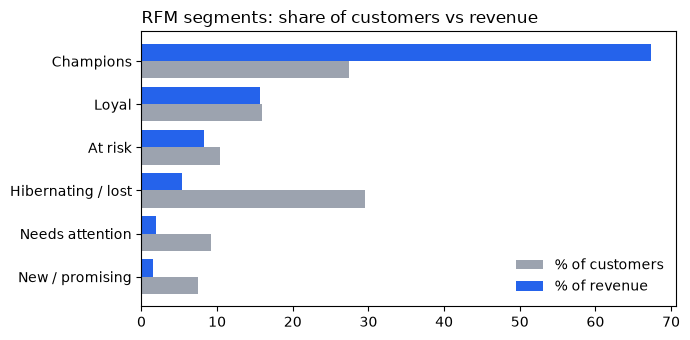

In [8]:
r = rfm.sort_values("pct_revenue")
y = np.arange(len(r))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(y - 0.2, r["pct_customers"], height=0.4, color="#9ca3af", label="% of customers")
ax.barh(y + 0.2, r["pct_revenue"],   height=0.4, color="#2563eb", label="% of revenue")
ax.set_yticks(y, r["segment"])
ax.legend(frameon=False, loc="lower right")
ax.set_title("RFM segments: share of customers vs revenue", loc="left")
plt.tight_layout()
plt.savefig(figs / "rfm.png", dpi=150)
plt.show()

Category Repeat Behaviour:
1. Category repeat rate: of customers who brought from a category, what % bought feom it on 2+ different days.
2. Same-item repeat rate: of all (customer,item) pairs, what% were brought on 2+ different days.

In [10]:
cat = run_sql("04_category_repurchase.sql")
cat

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,product_group_name,buyers,category_repeat_rate,same_item_repeat_rate
0,Garment Upper body,1092325,64.2,3.42
1,Garment Lower body,927480,61.4,5.80
2,Garment Full body,644925,53.7,4.62
3,Underwear,517715,51.2,3.55
4,Accessories,491251,47.3,1.99
5,Swimwear,426146,45.3,5.02
6,Shoes,269195,39.0,4.66
7,Socks & Tights,267096,34.3,5.20
8,Nightwear,169597,28.0,3.06
9,Unknown,64345,14.3,5.26


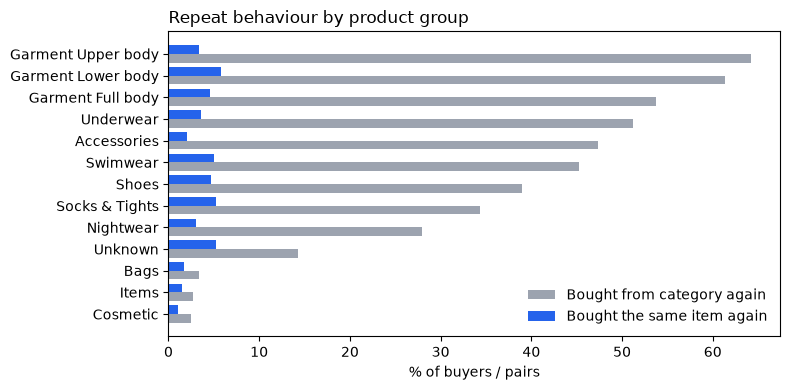

In [11]:
c = cat.sort_values("category_repeat_rate")
y = np.arange(len(c))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(y - 0.2, c["category_repeat_rate"],  height=0.4, color="#9ca3af", label="Bought from category again")
ax.barh(y + 0.2, c["same_item_repeat_rate"], height=0.4, color="#2563eb", label="Bought the same item again")
ax.set_yticks(y, c["product_group_name"])
ax.set_xlabel("% of buyers / pairs")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Repeat behaviour by product group", loc="left")
plt.tight_layout()
plt.savefig(figs / "category_repurchase.png", dpi=150)
plt.show()